In [1]:
import grsopt
import pandas as pd
import numpy as np

In [2]:
cd ~/workplace/T1D/

/public/wengjianping/zhengjy111/workplace/T1D


In [3]:
# Load the Chinese cohort training set (141 T1D and 386 HC) and independent validation set (107 T1D and 53 HC)
train_df=pd.read_csv('./data/sfware_test/train.csv',index_col=0)
val_df =pd.read_csv('./data/sfware_test/validation.csv',index_col=0)

In [4]:
X=train_df.drop('Disease',axis=1)
x_val=val_df.drop('Disease',axis=1)

y=train_df['Disease']
y_val=val_df['Disease']

In [5]:
X.head(2)

,1:113834946:A:G,1:206766559:G:A,2:162267541:C:T,2:203874196:G:A,4:122456825:A:C,6:29972123:C:T,6:90248512:C:G,6:126377573:A:G,7:50959497:A:C,10:6055320:T:C,...,20:1629905:T:C.1,6:159044945:T:C,14:100840110:T:C,12:9733403:G:A,1:206766559:G:A.1,2:162254026:A:G,2:203874196:G:A.1,16:11086016:A:G.1,19:10381598:C:T,10:6087680:C:T
0,2.0,0.0,0.0,0.0,0.0,0.0,1.0,2.0,2.0,0.0,...,1.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
1,2.0,0.0,0.0,0.0,1.0,0.0,1.0,2.0,2.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [6]:
y

0      T1D
1      T1D
2      T1D
3      T1D
4      T1D
      ... 
521     HC
522     HC
523     HC
524     HC
525     HC
Name: Disease, Length: 526, dtype: object

In [7]:
#Using SNPs and original betas from T1D GRS1 (Richard A Oram et al. 2016) and T1D GRS2 (Seth A Sharp et al. 2019)
beta_orign=pd.read_csv('./data/sfware_test/T1DGRS1&2_beta.csv',index_col=0)

## Grid search for hyperparameter tuning

In [8]:
mapping = {"HC": 0, "T1D": 1}
y =y.map(mapping)

In [9]:
grsopter=grsopt.grsoptimizer(original_betas=beta_orign['beta'])

In [10]:
param_grid = {
            'regularization_strength': [0.001, 0.01,0.1],
            'noise_scale' :[0.1,0.3,0.5],
        }

In [11]:
crs_val=grsopter.cross_validate(X, y, param_grid, cv_folds=5)

开始5折交叉验证，共有9组超参数组合...
原始模型测试集AUC: 0.7381
训练集AUC: 0.8996

=== 优化结果 ===
原始模型AUC: 0.7381
优化后AUC: 0.8996
AUC提升: 0.1616
原始模型测试集AUC: 0.7210
训练集AUC: 0.9027

=== 优化结果 ===
原始模型AUC: 0.7210
优化后AUC: 0.9027
AUC提升: 0.1817
原始模型测试集AUC: 0.6913
训练集AUC: 0.8948

=== 优化结果 ===
原始模型AUC: 0.6913
优化后AUC: 0.8948
AUC提升: 0.2035
原始模型测试集AUC: 0.7247
训练集AUC: 0.9088

=== 优化结果 ===
原始模型AUC: 0.7247
优化后AUC: 0.9088
AUC提升: 0.1841
原始模型测试集AUC: 0.7083
训练集AUC: 0.8951

=== 优化结果 ===
原始模型AUC: 0.7083
优化后AUC: 0.8951
AUC提升: 0.1868
参数{'regularization_strength': 0.001, 'noise_scale': 0.1}的平均验证集AUC: 0.8238
原始模型测试集AUC: 0.7381
训练集AUC: 0.8996

=== 优化结果 ===
原始模型AUC: 0.7381
优化后AUC: 0.8996
AUC提升: 0.1616
原始模型测试集AUC: 0.7210
训练集AUC: 0.9027

=== 优化结果 ===
原始模型AUC: 0.7210
优化后AUC: 0.9027
AUC提升: 0.1817
原始模型测试集AUC: 0.6913
训练集AUC: 0.8948

=== 优化结果 ===
原始模型AUC: 0.6913
优化后AUC: 0.8948
AUC提升: 0.2035
原始模型测试集AUC: 0.7247
训练集AUC: 0.9088

=== 优化结果 ===
原始模型AUC: 0.7247
优化后AUC: 0.9088
AUC提升: 0.1841
原始模型测试集AUC: 0.7083
训练集AUC: 0.8951

=== 优化结果 ===
原始模型AUC: 0.7083
优化后

In [12]:
crs_val

{'best_params': {'regularization_strength': 0.01, 'noise_scale': 0.5},
 'best_auc': np.float64(0.8250463821892394)}

## Perform hyperparameter optimization

In [13]:
grsopter=grsopt.grsoptimizer(original_betas=beta_orign['beta'],
                             regularization_strength=0.01,
                             noise_scale=0.5,n_intial=500,max_iter=10000)

In [14]:
result=grsopter.optimize(X, y)

原始模型测试集AUC: 0.7168
训练集AUC: 0.8790

=== 优化结果 ===
原始模型AUC: 0.7168
优化后AUC: 0.8790
AUC提升: 0.1622


In [15]:
GRS_train_ori=np.dot(X,beta_orign['beta'])
GRS_train_opt=np.dot(X,result['optimized_betas'])
from sklearn.metrics import roc_auc_score
auc_baseline=roc_auc_score(y,GRS_train_ori)
auc_optimized=roc_auc_score(y,GRS_train_opt)
auc_improvement = auc_optimized - auc_baseline
print(f"Training set baseline AUC: {auc_baseline:.2f}")
print(f"Training set optimized AUC: {auc_optimized:.2f}")
print(f"Training set AUC gain: {auc_improvement:.2f}")

Training set baseline AUC: 0.72
Training set optimized AUC: 0.88
Training set AUC gain: 0.16


In [16]:
GRS_val_ori=np.dot(x_val,beta_orign['beta'])
GRS_val_opt=np.dot(x_val,result['optimized_betas'])
auc_baseline=roc_auc_score(y_val,GRS_val_ori)
auc_optimized=roc_auc_score(y_val,GRS_val_opt)
auc_improvement = auc_optimized - auc_baseline
print(f"Validation set baseline AUC: {auc_baseline:.2f}")
print(f"Validation set optimized AUC: {auc_optimized:.2f}")
print(f"Validation set AUC gain: {auc_improvement:.2f}")

Validation set baseline AUC: 0.68
Validation set optimized AUC: 0.79
Validation set AUC gain: 0.12


## Plotting

In [17]:
GRS_val_opt_df=pd.DataFrame({'grs':GRS_val_opt,'Disease':y_val.to_list()})
GRS_val_ori_df=pd.DataFrame({'grs':GRS_val_ori,'Disease':y_val.to_list()})

#### Validation set before optimization

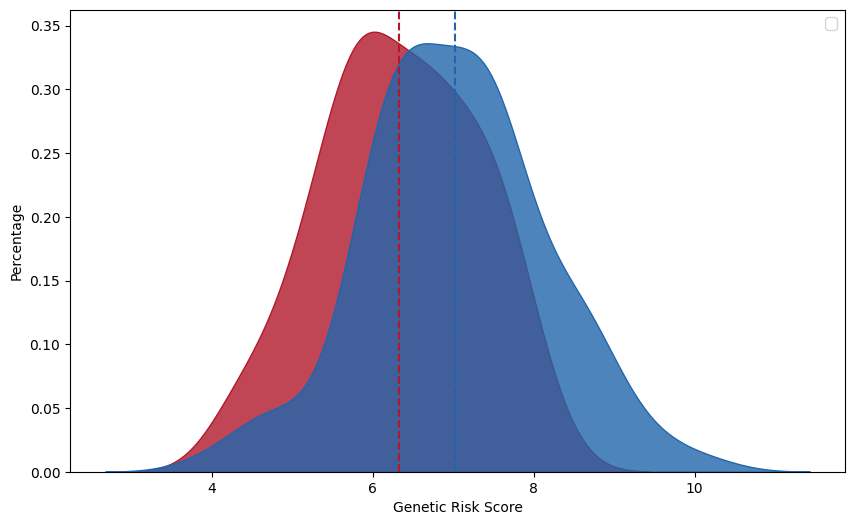

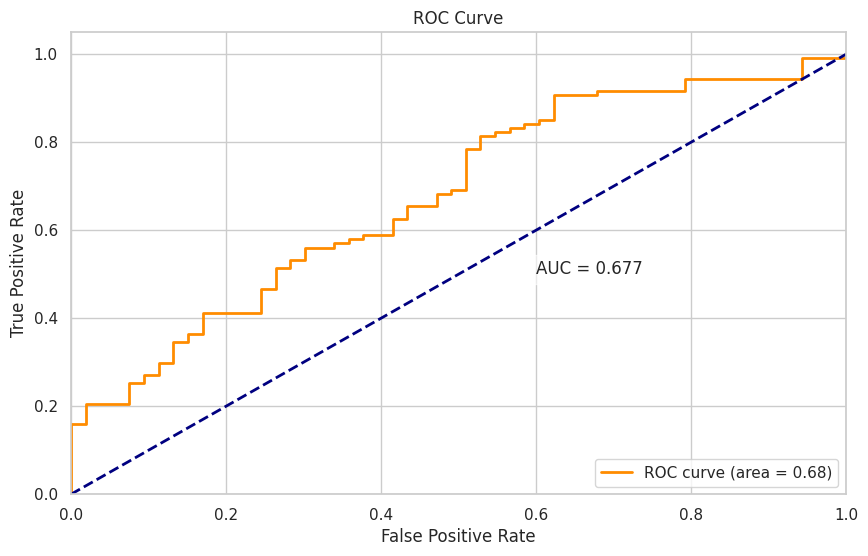

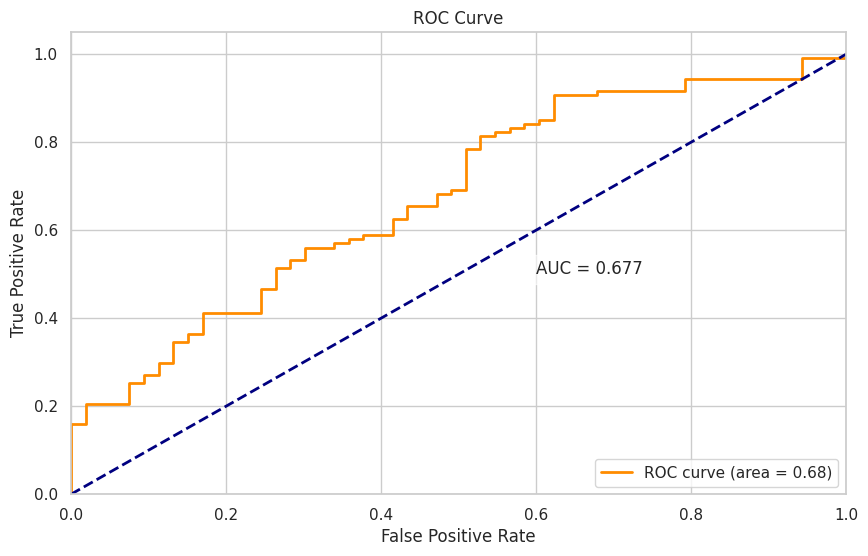

In [18]:
grsopt.GRS_pic(GRS_val_ori_df,model_name='origin')
grsopt.ROC_pic(GRS_val_ori_df,model_name='origin')

#### Validation set after optimization

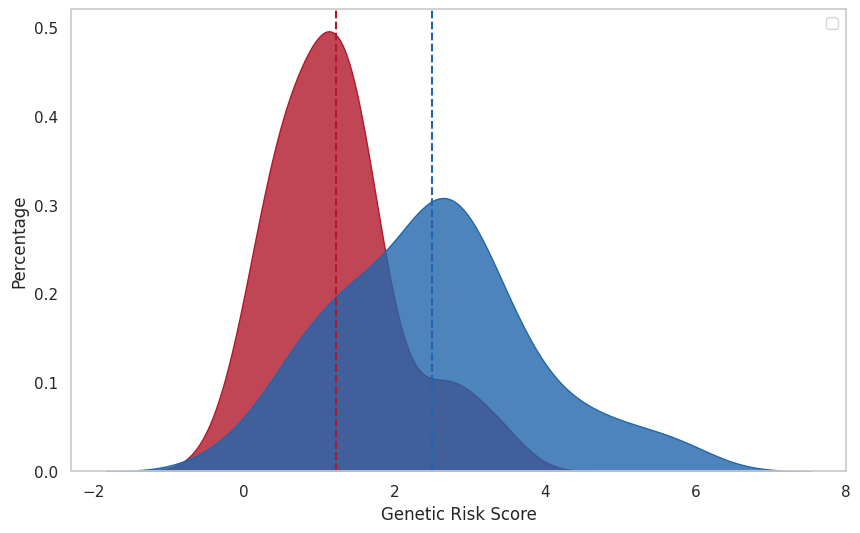

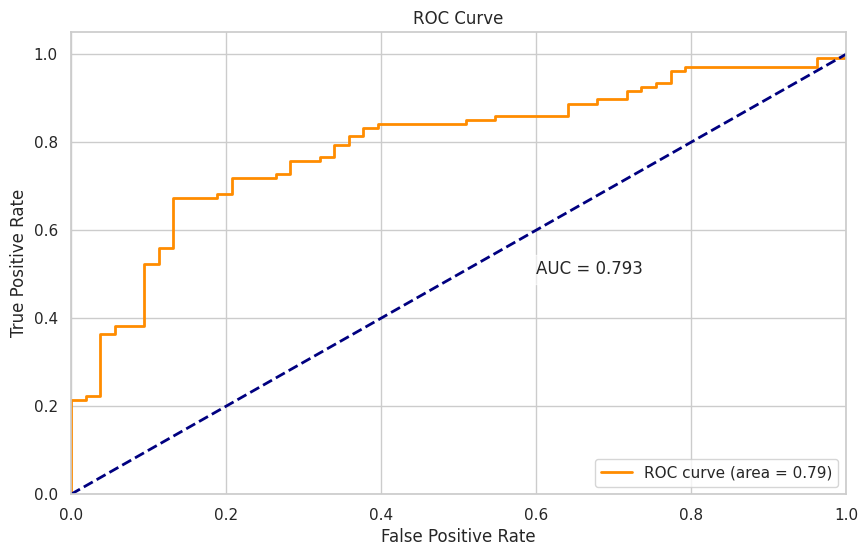

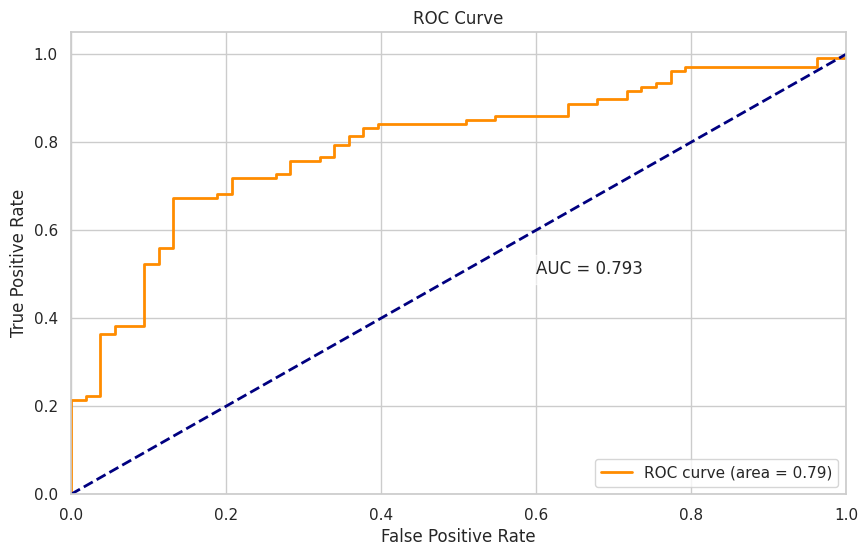

In [19]:
grsopt.GRS_pic(GRS_val_opt_df,model_name='origin')
grsopt.ROC_pic(GRS_val_opt_df,model_name='origin')